In [ ]:
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk import pos_tag, word_tokenize, ne_chunk
from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import spacy

In [2]:
import requests
import re

def clean_bounds(text):
    start_idx = text.find('*** START')
    end_idx   = text.find('*** END')
    if start_idx != -1 and end_idx != -1:
        text = text[start_idx:end_idx]
    return text

def load_texts(urls: list) -> list:
    corpus: list = []
    for url in urls:
        try:
            response = requests.get(url, timeout=30)
            response.raise_for_status()
            text = requests.get(url).text
            text = clean_bounds(text)

            text = re.sub(r"[^a-zA-ZÀ-ÿ'\s]", " ", text)
            text = re.sub(r"[\r\n]+", " ", text)
            
            corpus.append(text)
        except requests.RequestException as e:
            print(f"Erreur {url} : {e}")
    return corpus

In [3]:
urls = [
    "https://www.gutenberg.org/cache/epub/11/pg11.txt",
    "https://www.gutenberg.org/cache/epub/12/pg12.txt",
    "https://www.gutenberg.org/cache/epub/29042/pg29042.txt",
]

corpus = load_texts(urls)
print([text[:200] for text in corpus ])

["    START OF THE PROJECT GUTENBERG EBOOK ALICE'S ADVENTURES IN WONDERLAND      Illustration  Alice s Adventures in Wonderland by Lewis Carroll THE MILLENNIUM FULCRUM EDITION     Contents  CHAPTER I   ", '    START OF THE PROJECT GUTENBERG EBOOK THROUGH THE LOOKING GLASS      Illustration  THROUGH THE LOOKING GLASS And What Alice Found There By Lewis Carroll The Millennium Fulcrum Edition     DRAMATIS ', '    START OF THE PROJECT GUTENBERG EBOOK A TANGLED TALE     Produced by Chris Curnow  Carla Foust  Lindy Walsh and the Online Distributed Proofreading Team at https   www pgdp net  Music transcribed b']


In [4]:
tokenized = [word_tokenize(t.lower()) for t in corpus]

for i, tokens in enumerate(tokenized):
    print(f'Book {i} | first 150 tokens')
    print(tokens[:150])
    print('-' * 40)

Book 0 | first 150 tokens
['start', 'of', 'the', 'project', 'gutenberg', 'ebook', 'alice', "'s", 'adventures', 'in', 'wonderland', 'illustration', 'alice', 's', 'adventures', 'in', 'wonderland', 'by', 'lewis', 'carroll', 'the', 'millennium', 'fulcrum', 'edition', 'contents', 'chapter', 'i', 'down', 'the', 'rabbit', 'hole', 'chapter', 'ii', 'the', 'pool', 'of', 'tears', 'chapter', 'iii', 'a', 'caucus', 'race', 'and', 'a', 'long', 'tale', 'chapter', 'iv', 'the', 'rabbit', 'sends', 'in', 'a', 'little', 'bill', 'chapter', 'v', 'advice', 'from', 'a', 'caterpillar', 'chapter', 'vi', 'pig', 'and', 'pepper', 'chapter', 'vii', 'a', 'mad', 'tea', 'party', 'chapter', 'viii', 'the', 'queen', 's', 'croquet', 'ground', 'chapter', 'ix', 'the', 'mock', 'turtle', 's', 'story', 'chapter', 'x', 'the', 'lobster', 'quadrille', 'chapter', 'xi', 'who', 'stole', 'the', 'tarts', 'chapter', 'xii', 'alice', 's', 'evidence', 'chapter', 'i', 'down', 'the', 'rabbit', 'hole', 'alice', 'was', 'beginning', 'to', 'get'

In [5]:
filtered_tokens = []
stop_words = set(stopwords.words('english'))

for tokens in tokenized:
    keep = [tok for tok in tokens if tok.isalpha() and tok not in stop_words]
    filtered_tokens.append(keep)

check_words = ['i', 'me', 'my', 'myself', 'we', 'our', 'ours', 'ourselves']
for i, tokens in enumerate(filtered_tokens):
    counts = {w: tokens.count(w) for w in check_words}
    print(f'Book {i} stopword counts:', counts)

print('\nBook 0:', len(tokenized[0]), 'tokens ->', len(filtered_tokens[0]), 'after filtering')

Book 0 stopword counts: {'i': 0, 'me': 0, 'my': 0, 'myself': 0, 'we': 0, 'our': 0, 'ours': 0, 'ourselves': 0}
Book 1 stopword counts: {'i': 0, 'me': 0, 'my': 0, 'myself': 0, 'we': 0, 'our': 0, 'ours': 0, 'ourselves': 0}
Book 2 stopword counts: {'i': 0, 'me': 0, 'my': 0, 'myself': 0, 'we': 0, 'our': 0, 'ours': 0, 'ourselves': 0}

Book 0: 27439 tokens -> 12312 after filtering


In [6]:
stemmer = PorterStemmer()
stemmed_tokens = [[stemmer.stem(t) for t in tokens] for tokens in filtered_tokens]

for i, stems in enumerate(stemmed_tokens):
    print(f'Book {i} | first 50 stems:', stems[:50])

Book 0 | first 50 stems: ['start', 'project', 'gutenberg', 'ebook', 'alic', 'adventur', 'wonderland', 'illustr', 'alic', 'adventur', 'wonderland', 'lewi', 'carrol', 'millennium', 'fulcrum', 'edit', 'content', 'chapter', 'rabbit', 'hole', 'chapter', 'ii', 'pool', 'tear', 'chapter', 'iii', 'caucu', 'race', 'long', 'tale', 'chapter', 'iv', 'rabbit', 'send', 'littl', 'bill', 'chapter', 'v', 'advic', 'caterpillar', 'chapter', 'vi', 'pig', 'pepper', 'chapter', 'vii', 'mad', 'tea', 'parti', 'chapter']
Book 1 | first 50 stems: ['start', 'project', 'gutenberg', 'ebook', 'look', 'glass', 'illustr', 'look', 'glass', 'alic', 'found', 'lewi', 'carrol', 'millennium', 'fulcrum', 'edit', 'dramati', 'personæ', 'arrang', 'commenc', 'game', 'white', 'red', 'piec', 'pawn', 'pawn', 'piec', 'tweedlede', 'daisi', 'daisi', 'humpti', 'dumpti', 'unicorn', 'haigha', 'messeng', 'carpent', 'sheep', 'oyster', 'oyster', 'walru', 'w', 'queen', 'lili', 'tiger', 'lili', 'r', 'queen', 'w', 'king', 'fawn']
Book 2 | first

In [7]:
lemmatized_tokens = []
nlp = spacy.load('en_core_web_sm')

for text in corpus:
    doc = nlp(text)
    lemmas = [tok.lemma_.lower() for tok in doc
              if tok.is_alpha and tok.text.lower() not in stop_words]
    lemmatized_tokens.append(lemmas)

for i, lemmas in enumerate(lemmatized_tokens):
    print(f'Book {i} | first 50 lemmas:', lemmas[:50])

Book 0 | first 50 lemmas: ['start', 'project', 'gutenberg', 'ebook', 'alice', 'adventures', 'wonderland', 'illustration', 'alice', 'adventures', 'wonderland', 'lewis', 'carroll', 'millennium', 'fulcrum', 'edition', 'contents', 'chapter', 'rabbit', 'hole', 'chapter', 'ii', 'pool', 'tears', 'chapter', 'iii', 'caucus', 'race', 'long', 'tale', 'chapter', 'iv', 'rabbit', 'send', 'little', 'bill', 'chapter', 'v', 'advice', 'caterpillar', 'chapter', 'vi', 'pig', 'pepper', 'chapter', 'vii', 'mad', 'tea', 'party', 'chapter']
Book 1 | first 50 lemmas: ['start', 'project', 'gutenberg', 'ebook', 'looking', 'glass', 'illustration', 'looking', 'glass', 'alice', 'find', 'lewis', 'carroll', 'millennium', 'fulcrum', 'edition', 'dramatis', 'personæ', 'arrange', 'commencement', 'game', 'white', 'red', 'pieces', 'pawns', 'pawns', 'pieces', 'tweedledee', 'daisy', 'daisy', 'humpty', 'dumpty', 'unicorn', 'haigha', 'messenger', 'carpenter', 'sheep', 'oyster', 'oyster', 'walrus', 'w', 'queen', 'lily', 'tiger',

Stemming don't understand the meanning of words, so he can't manage words like "alic", "piec", etc
Lemmatized_tokens use a model to understand the grammar and the context.

In [ ]:
for i, tokens in enumerate(filtered_tokens):
    tagged = pos_tag(tokens[:120])
    print(f'Book {i} POS (first 120):')
    print(tagged)
    print('-' * 40)

Book 0 POS (first 120):
[('start', 'NN'), ('project', 'NN'), ('gutenberg', 'NN'), ('ebook', 'NN'), ('alice', 'NN'), ('adventures', 'NNS'), ('wonderland', 'VBP'), ('illustration', 'NN'), ('alice', 'NN'), ('adventures', 'NNS'), ('wonderland', 'VBP'), ('lewis', 'JJ'), ('carroll', 'NN'), ('millennium', 'NN'), ('fulcrum', 'NN'), ('edition', 'NN'), ('contents', 'NNS'), ('chapter', 'NN'), ('rabbit', 'NN'), ('hole', 'JJ'), ('chapter', 'NN'), ('ii', 'NN'), ('pool', 'NN'), ('tears', 'NNS'), ('chapter', 'NN'), ('iii', 'VBP'), ('caucus', 'NN'), ('race', 'NN'), ('long', 'JJ'), ('tale', 'JJ'), ('chapter', 'NN'), ('iv', 'NN'), ('rabbit', 'NN'), ('sends', 'VBZ'), ('little', 'JJ'), ('bill', 'NN'), ('chapter', 'NN'), ('v', 'NN'), ('advice', 'NN'), ('caterpillar', 'JJ'), ('chapter', 'NN'), ('vi', 'NN'), ('pig', 'NN'), ('pepper', 'IN'), ('chapter', 'NN'), ('vii', 'NN'), ('mad', 'JJ'), ('tea', 'NN'), ('party', 'NN'), ('chapter', 'NN'), ('viii', 'NN'), ('queen', 'JJ'), ('croquet', 'NN'), ('ground', 'NN'), (

In [ ]:
def extract_entities(tokens):
    tree = ne_chunk(pos_tag(tokens), binary=False)
    ents = []
    for chunk in tree:
        if hasattr(chunk, 'label'):
            ent_text = ' '.join(c[0] for c in chunk.leaves())
            ents.append((ent_text, chunk.label()))
    return ents

for i, tokens in enumerate(filtered_tokens):
    ents = extract_entities(tokens[:500])
    print(f'Book {i} entities (sample): {ents[:30]}')

Book 0 entities (sample): []
Book 1 entities (sample): []
Book 2 entities (sample): []


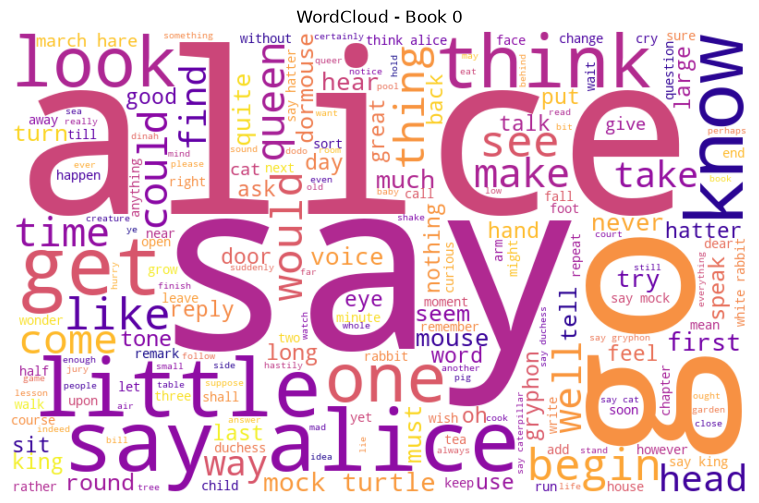

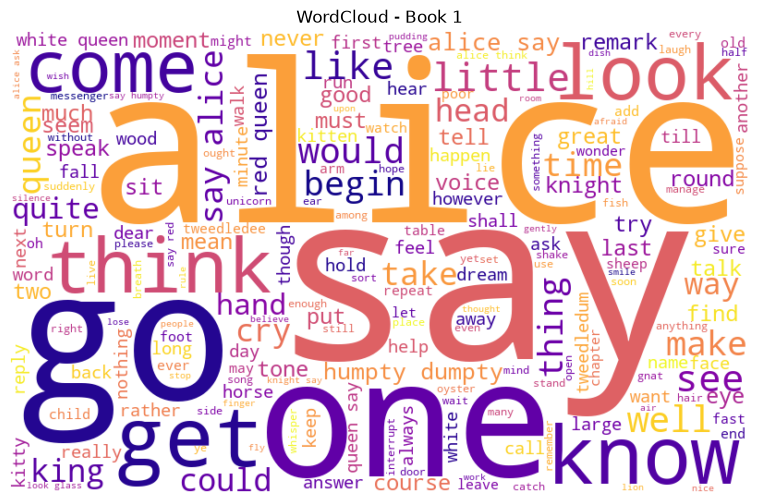

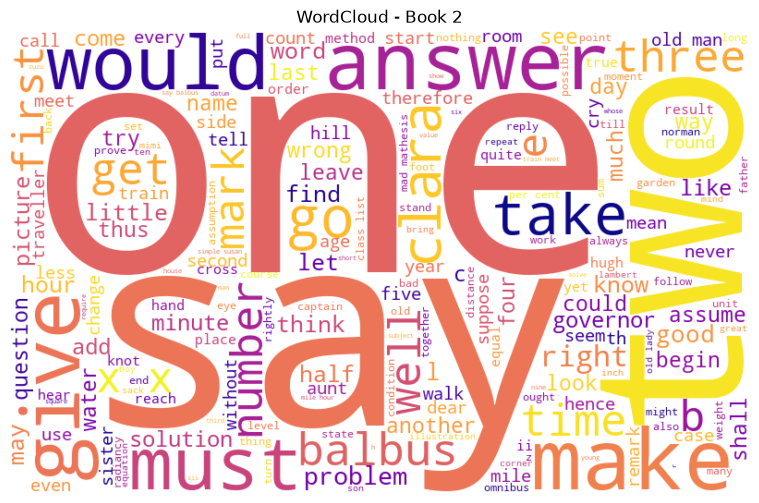

In [10]:
wc_stopwords = set(stop_words)

for i, tokens in enumerate(lemmatized_tokens):
    text_blob = ' '.join(tokens)
    wc = WordCloud(width=800, height=500, background_color='white',
                   stopwords=wc_stopwords, colormap='plasma').generate(text_blob)
    plt.figure(figsize=(10, 6))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'WordCloud - Book {i}')
    plt.show()

In [12]:
import pandas as pd

vectorizer = CountVectorizer()
bow_matrix = vectorizer.fit_transform(corpus)

word_counts = bow_matrix.sum(axis=0).A1
words = vectorizer.get_feature_names_out()

freq_df = pd.DataFrame({'word': words, 'count': word_counts})
top5 = freq_df.sort_values('count', ascending=False).head(5)
print(top5)

     word  count
5334  the   5003
183   and   2583
5434   to   2105
3625   of   1786
2805   it   1631


In [13]:
lemmatized_texts = [' '.join(lemmas) for lemmas in lemmatized_tokens]

vectorizer = CountVectorizer()
bow_matrix = vectorizer.fit_transform(lemmatized_texts)

word_counts = bow_matrix.sum(axis=0).A1
words = vectorizer.get_feature_names_out()

freq_df = pd.DataFrame({'word': words, 'count': word_counts})
top5 = freq_df.sort_values('count', ascending=False).head(5)
print(top5)

       word  count
3451    say   1311
117   alice    872
2776    one    474
1735     go    438
1701    get    314


In [14]:
print(bow_matrix)

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 7034 stored elements and shape (3, 4595)>
  Coords	Values
  (0, 3795)	2
  (0, 3097)	1
  (0, 1814)	1
  (0, 1252)	1
  (0, 117)	400
  (0, 71)	3
  (0, 4524)	4
  (0, 2006)	1
  (0, 2304)	1
  (0, 584)	1
  (0, 2527)	1
  (0, 1647)	1
  (0, 1260)	3
  (0, 843)	1
  (0, 625)	24
  (0, 3194)	54
  (0, 1926)	6
  (0, 2001)	2
  (0, 3017)	12
  (0, 3980)	2
  (0, 2002)	2
  (0, 600)	4
  (0, 3195)	7
  (0, 2364)	38
  (0, 3954)	6
  :	:
  (2, 3385)	1
  (2, 3305)	1
  (2, 758)	1
  (2, 2931)	1
  (2, 3000)	1
  (2, 1979)	1
  (2, 2597)	2
  (2, 3306)	1
  (2, 4118)	1
  (2, 2505)	2
  (2, 2)	1
  (2, 862)	2
  (2, 1110)	2
  (2, 2882)	1
  (2, 3129)	1
  (2, 3308)	1
  (2, 1245)	1
  (2, 1778)	1
  (2, 2273)	1
  (2, 1622)	1
  (2, 1853)	1
  (2, 2838)	1
  (2, 2417)	1
  (2, 2269)	2
  (2, 298)	1


In [17]:
print(vectorizer.get_feature_names_out()[117])

alice


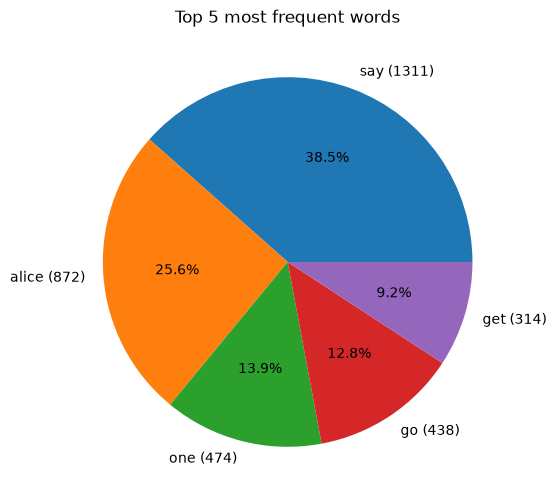

In [18]:
plt.figure(figsize=(6,6))
plt.pie(
    top5['count'],
    labels=[f"{word} ({count})" for word, count in zip(top5['word'], top5['count'])],
    autopct='%1.1f%%'
)
plt.title('Top 5 most frequent words')
plt.show()